# Section 9 — Lagrange Interpolation at Chebyshev Roots
**MAD 4401 · Introduction to Numerical Analysis**

An interactive Python adaptation of `lagrange_interp.m` and `cheby_lagrange.m`
by **Sarah Pollock** (credited as S. Pollock in the source files).

An interpolating polynomial passes through every data point. That does **not** mean it
approximates the function well between those points. In this notebook we will:

1. See how equally spaced and randomly spaced nodes can produce large errors.
2. Use the interpolation remainder to identify the part we can control by moving the nodes.
3. Define Chebyshev polynomials and explain their minimax property.
4. Compare node choices, examine a rigorous error bound, and revisit the random-data experiment.

**How to use this notebook.** Open it in Jupyter Notebook or JupyterLab with a Python 3 kernel,
then choose **Run All**. Move a slider or choose a menu item to update its plots.
Sliders update when released. The saved figures are starting views; controls become active
after you run the cells. Plotting helpers may start collapsed; expand them to inspect the code.

[← Module 2](README.md) · [Review Lagrange interpolation](01_lagrange_interpolation.ipynb)

**Suggested reading order:** work through this extension after Sections 1–2.
On GitHub you can read all saved figures without running code. For live controls,
open the notebook in JupyterLab, Binder, or Colab and run all cells from the top.


## Setup

We use NumPy for arrays, Matplotlib for graphs, SciPy for polynomial evaluation, and
`ipywidgets` for the controls. If an import fails, uncomment and run the installation
line below, restart the kernel, and run the notebook again.
No MATLAB files, data downloads, or API keys are needed.

In [1]:
# Uncomment only if these packages are missing from your notebook environment:
# %pip install numpy matplotlib scipy ipywidgets

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator
from IPython.display import display, Markdown

try:
    import ipywidgets as widgets
except ImportError:
    widgets = None
    print(
        "ipywidgets is missing: saved/default examples still work. Install it"
        " for sliders."
    )

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.23,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Each node family has both a different color and a different marker.
COLORS = {
    "Equally spaced": "#0072B2",
    "Random": "#D55E00",
    "Chebyshev": "#00856A",
}
MARKERS = {"Equally spaced": "s", "Random": "^", "Chebyshev": "o"}


## 1. What are we constructing?

Choose **$m=n+1$ distinct interpolation nodes** $x_0,\ldots,x_n$ and sample
$y_j=f(x_j)$. There is a unique polynomial $p_n$ of degree **at most** $n$ satisfying
$p_n(x_j)=y_j$. Its Lagrange form is

$$p_n(x)=\sum_{j=0}^{n}y_jL_j(x),\qquad
L_j(x)=\prod_{\substack{k=0\\k\ne j}}^{n}\frac{x-x_k}{x_j-x_k}.$$

The basis polynomial $L_j$ equals $1$ at its own node and $0$ at every other node.
Thus the sum reproduces each prescribed data value. We use **one global polynomial**
on the entire interval, rather than a different polynomial on each subinterval.

| Symbol / code parameter | Meaning |
|---|---|
| `n` | Maximum degree of the interpolant $p_n$ |
| `m = n + 1` | Number of interpolation nodes; this is the input `m` in the MATLAB files |
| `a`, `b` | Left and right endpoints of the interval; $a<b$ |
| `nodes` or $x_j$ | Locations where we know or sample the function |
| `values` or $y_j$ | Function values or supplied data at those nodes |
| `z` | A dense evaluation grid used to draw curves and estimate maximum errors |
| `grid_size` | Number of evaluation points; changing it does **not** add interpolation nodes |
| `seed` | Reproducible random-number seed; changing it gives a different random node set |
| `pin_endpoints` | If selected, random nodes include $a$ and $b$, with $m-2$ random interior nodes |
| `alpha` | Parameter in $f(x)=1/(1+\alpha x^2)$; larger $\alpha$ makes the peak narrower |

The code evaluates the same Lagrange interpolant in **barycentric form**, avoiding
expansion into powers of $x$. This improves numerical evaluation; it does not change the
mathematical polynomial or remove a poor choice of nodes.

In [2]:
def map_to_interval(t, a=-1.0, b=1.0):
    """Map t in [-1, 1] to x in [a, b]."""
    if not a < b:
        raise ValueError("Require a < b.")
    return (a + b) / 2 + (b - a) / 2 * np.asarray(t)


def make_nodes(kind, n, a=-1.0, b=1.0, seed=7, pin_endpoints=False):
    """Return n+1 distinct nodes. Chebyshev means roots of T_(n+1)."""
    if int(n) != n or n < 1:
        raise ValueError("n must be a positive integer.")
    m = int(n) + 1
    if kind == "Equally spaced":
        t = np.linspace(-1, 1, m)
    elif kind == "Random":
        rng = np.random.default_rng(seed)
        if pin_endpoints:
            t = np.r_[-1.0, np.sort(rng.uniform(-1, 1, m - 2)), 1.0]
        else:
            t = np.sort(rng.uniform(-1, 1, m))
    elif kind == "Chebyshev":
        j = np.arange(m)
        t = np.sort(np.cos((2 * j + 1) * np.pi / (2 * m)))
    else:
        raise ValueError("Unknown node family.")
    nodes = map_to_interval(t, a, b)
    if np.unique(nodes).size != m:
        raise ValueError("Repeated nodes: choose another random seed.")
    return nodes


def interpolate(nodes, values, z):
    """Evaluate the Lagrange polynomial using barycentric weights."""
    nodes = np.asarray(nodes, dtype=float)
    values = np.asarray(values, dtype=float)
    if nodes.ndim != 1 or nodes.size == 0:
        raise ValueError("nodes must be a nonempty one-dimensional array.")
    if values.shape != nodes.shape:
        raise ValueError("Provide one scalar value for each node.")
    if not np.all(np.isfinite(nodes)) or not np.all(np.isfinite(values)):
        raise ValueError("Nodes and values must be finite.")
    if np.unique(nodes).size != nodes.size:
        raise ValueError("Interpolation nodes must be distinct.")
    if nodes.size == 1:
        return np.full_like(np.asarray(z, dtype=float), values[0])
    # w_j = 1 / product_(k != j)(x_j - x_k).
    # Scaling all weights by the same factor leaves the interpolant unchanged.
    scale = (nodes.max() - nodes.min()) / 2
    differences = (nodes[:, None] - nodes[None, :]) / scale
    np.fill_diagonal(differences, 1.0)
    weights = 1.0 / np.prod(differences, axis=1)
    weights /= np.max(np.abs(weights))
    p = BarycentricInterpolator(nodes, values, wi=weights)
    return np.asarray(p(z))


def node_product(z, nodes):
    """omega_(n+1)(z) = product_j (z - x_j)."""
    return np.prod(np.asarray(z)[..., None] - np.asarray(nodes), axis=-1)


def chebyshev_T(k, t):
    """Evaluate T_k by its three-term recurrence (no arccos needed)."""
    t = np.asarray(t, dtype=float)
    previous = np.ones_like(t)  # T_0
    if k == 0:
        return previous
    current = t.copy()  # T_1
    for degree in range(1, k):
        previous, current = current, 2 * t * current - previous
    return current


def optimal_product_norm(n, a=-1.0, b=1.0):
    """Exact smallest possible sup norm of a monic nodal polynomial."""
    return ((b - a) / 2) ** (n + 1) * 2.0 ** (-n)


def markdown_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    return "\n".join(lines)


def show_result(result):
    """Display a plot and its text summary without widgets."""
    fig, summary = result
    display(fig)
    plt.close(fig)
    display(Markdown(summary))


def control(kind, value, **kwargs):
    """Widget specification that also works when ipywidgets is absent."""
    return (kind, value, kwargs)


def interactive_demo(draw, specs):
    """Show live controls and save ordinary figure/text outputs."""
    defaults = {name: spec[1] for name, spec in specs.items()}
    if widgets is None:
        show_result(draw(**defaults))
        return None

    controls = {}
    for name, (kind, value, options) in specs.items():
        options = dict(options)
        options.setdefault("description", name)
        options["style"] = {"description_width": "initial"}
        options["layout"] = widgets.Layout(width="310px")
        if kind in ("IntSlider", "FloatSlider"):
            options["continuous_update"] = False
        controls[name] = getattr(widgets, kind)(value=value, **options)

    box = widgets.Box(
        list(controls.values()),
        layout=widgets.Layout(display="flex", flex_flow="row wrap", gap="6px"),
    )
    status = widgets.HTML()
    display(box, status)
    fig, summary = draw(**defaults)
    figure_handle = display(fig, display_id=True)
    plt.close(fig)
    text_handle = display(Markdown(summary), display_id=True)

    def update(change):
        status.value = ""
        try:
            values = {name: item.value for name, item in controls.items()}
            fig, summary = draw(**values)
            figure_handle.update(fig)
            plt.close(fig)
            text_handle.update(Markdown(summary))
        except Exception as exc:
            import html

            status.value = "<b>Could not update:</b> " + html.escape(str(exc))

    for item in controls.values():
        item.observe(update, names="value")
    return controls


### A small Lagrange calculation before the experiments

For nodes $-1,0,1$ and values $1,0,1$, the unique interpolant is $p_2(x)=x^2$.
The nested loops below implement the displayed Lagrange basis directly, just as
in Pollock's demonstrations. We use this transparent version for a small example;
the larger experiments use the barycentric evaluator above for better numerical
stability. Both formulas represent the same polynomial.


In [3]:
def lagrange_direct(nodes, values, z):
    """Evaluate the Lagrange basis formula for a small teaching example."""
    z = np.asarray(z, dtype=float)
    result = np.zeros_like(z)
    for j, xj in enumerate(nodes):
        basis = np.ones_like(z)
        for k, xk in enumerate(nodes):
            if k != j:
                basis *= (z - xk) / (xj - xk)
        result += values[j] * basis
    return result


example_nodes = np.array([-1.0, 0.0, 1.0])
example_values = example_nodes**2
sample_points = np.array([-0.5, 0.0, 0.5])
direct_values = lagrange_direct(example_nodes, example_values, sample_points)
barycentric_values = interpolate(example_nodes, example_values, sample_points)
display(
    Markdown(
        markdown_table(
            ["x", "Lagrange basis", "Barycentric form", "x²"],
            [
                [f"{x:g}", f"{d:g}", f"{b:g}", f"{x * x:g}"]
                for x, d, b in zip(
                    sample_points, direct_values, barycentric_values
                )
            ],
        )
    )
)


| x | Lagrange basis | Barycentric form | x² |
| --- | --- | --- | --- |
| -0.5 | 0.25 | 0.25 | 0.25 |
| 0 | 0 | 0 | 0 |
| 0.5 | 0.25 | 0.25 | 0.25 |

## 2. First experiment: equal spacing and randomness can both fail

Start with the **Runge function**

$$f(x)=\frac{1}{1+25x^2},\qquad -1\le x\le1.$$

For each node family, we sample **this same function** and construct the interpolant.
The top row shows the function, the interpolating polynomial, and its data points.
The bottom row shows the **absolute error** $|f(x)-p_n(x)|$ on a logarithmic scale.

Start with $n=12$ ($m=13$ nodes), then try $n=4,8,16,20$. Change the random seed too.
The plots use separate vertical scales so the function is not hidden by the worst curve;
compare the numerical errors in the table. No vertical clipping is used.

**Prediction:** Will adding interpolation points necessarily make the largest error smaller?

Box(children=(IntSlider(value=12, continuous_update=False, description='Degree n', layout=Layout(width='310px'…

HTML(value='')

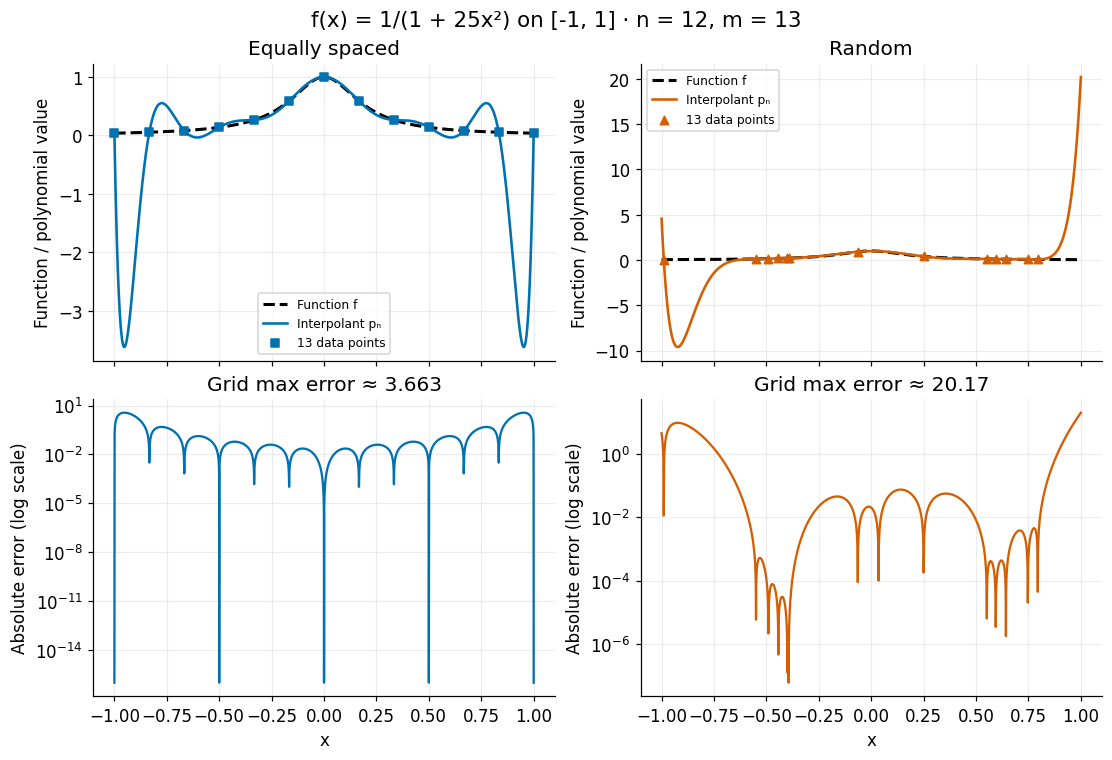

| Nodes | Max error on grid (estimate) | Grid location of max | Residual at data nodes |
| --- | --- | --- | --- |
| Equally spaced | 3.66338 | -0.95250 | 0.00e+00 |
| Random | 20.174 | 1.00000 | 0.00e+00 |

Errors are sampled at 4,001 evaluation points, including interval endpoints. They are estimates of the continuous maximum, not rigorous bounds. Values below 10⁻¹⁶ are drawn at 10⁻¹⁶ only on the log plots; the table uses unmodified errors. Random nodes usually leave unsampled gaps at both ends; evaluating there is extrapolation beyond the outermost sampled nodes, even though it is inside the target interval.

In [4]:
def compare_interpolants(
    n=12,
    seed=7,
    alpha=25,
    pin_endpoints=False,
    include_chebyshev=False,
    function="Runge",
    a=-1.0,
    b=1.0,
    grid_size=4001,
):
    families = ["Equally spaced", "Random"]
    if include_chebyshev:
        families.append("Chebyshev")
    if function == "Runge":

        def f(x):
            return 1 / (1 + alpha * np.asarray(x) ** 2)

        formula = f"f(x) = 1/(1 + {alpha}x²)"
    elif function == "Exponential":
        f = np.exp
        formula = "f(x) = exp(x)"
    elif function == "Absolute value":
        f = np.abs
        formula = "f(x) = |x|"
    else:
        raise ValueError("Unknown function.")

    z = np.linspace(a, b, grid_size)
    exact = f(z)
    fig, axes = plt.subplots(
        2,
        len(families),
        figsize=(5 * len(families), 6.8),
        sharex=True,
        layout="constrained",
    )
    rows = []
    for col, family in enumerate(families):
        nodes = make_nodes(family, n, a, b, seed, pin_endpoints)
        values = f(nodes)
        approximation = interpolate(nodes, values, z)
        error = np.abs(exact - approximation)
        ax, ax_error = axes[:, col]
        ax.plot(z, exact, color="black", ls="--", lw=2, label="Function f")
        ax.plot(
            z,
            approximation,
            color=COLORS[family],
            lw=1.7,
            label="Interpolant pₙ",
        )
        ax.scatter(
            nodes,
            values,
            c=COLORS[family],
            marker=MARKERS[family],
            s=30,
            zorder=4,
            label=f"{n + 1} data points",
        )
        ax.set(title=family, ylabel="Function / polynomial value")
        ax.legend(fontsize=8, loc="best")
        ax_error.semilogy(z, np.maximum(error, 1e-16), color=COLORS[family])
        ax_error.set(
            xlabel="x",
            ylabel="Absolute error (log scale)",
            title=f"Grid max error ≈ {np.max(error):.4g}",
        )
        residual = np.max(np.abs(interpolate(nodes, values, nodes) - values))
        rows.append([
            family,
            f"{np.max(error):.6g}",
            f"{z[np.argmax(error)]:.5f}",
            (
                f"{residual:.2e}"
            ),
        ])
    fig.suptitle(
        f"{formula} on [{a:g}, {b:g}] · n = {n}, m = {n + 1}", fontsize=14
    )
    summary = markdown_table(
        [
            "Nodes",
            "Max error on grid (estimate)",
            "Grid location of max",
            "Residual at data nodes",
        ],
        rows,
    )
    summary += (
        f"\n\nErrors are sampled at {grid_size:,} evaluation points, including"
        " interval endpoints. They are estimates of the continuous maximum,"
        " not rigorous bounds. Values below 10⁻¹⁶ are drawn at 10⁻¹⁶ only on"
        " the log plots; the table uses unmodified errors."
    )
    if not pin_endpoints:
        summary += (
            " Random nodes usually leave unsampled gaps at both ends;"
            " evaluating there is extrapolation beyond the outermost sampled"
            " nodes, even though it is inside the target interval."
        )
    return fig, summary


baseline_controls = interactive_demo(
    compare_interpolants,
    {
        "n": control(
            "IntSlider", 12, min=2, max=24, step=1, description="Degree n"
        ),
        "seed": control(
            "IntSlider", 7, min=0, max=99, description="Random seed"
        ),
        "pin_endpoints": control(
            "Checkbox", False, description="Pin random endpoints"
        ),
    },
)


### What happened?

- Every interpolant fits its data values, yet it may oscillate greatly between them.
- For the Runge function, high-degree interpolation at equally spaced nodes develops
  large oscillations near the ends. This is the **Runge phenomenon**.
- Random placement is not a systematic cure: nodes can cluster, leave wide gaps, or
  fail to sample near the endpoints. Some random sets do better than others.
  Select **Pin random endpoints** to see that endpoint gaps are only part of the problem.

The claim is that equal spacing and randomness **can** produce large errors, not that
they always do. Equal spacing is perfectly effective in many small-degree examples.
Changing the random seed is an experiment, not an optimization algorithm.

**Discuss:** The data-node residuals are essentially zero. Why does that tell us so little
about the maximum error across the whole interval?

## 3. The error formula tells us what to minimize

Suppose $f\in C^{n+1}([a,b])$ and the $n+1$ nodes are distinct and lie in $[a,b]$.
For each $x\in[a,b]$ that is not a node, some $\xi_x\in(a,b)$ satisfies

$$\boxed{f(x)-p_n(x)=\frac{f^{(n+1)}(\xi_x)}{(n+1)!}
\underbrace{(x-x_0)(x-x_1)\cdots(x-x_n)}_{\displaystyle\omega_{n+1}(x)}.}$$

At a node both sides are zero. The unknown point $\xi_x$ generally depends on $x$,
the function, and the nodes; we cannot treat the derivative factor as a known constant.

| Part of the remainder | What it tells us |
|---|---|
| $f^{(n+1)}(\xi_x)$ | The function's higher-order variation matters |
| $(n+1)!$ | The factorial comes from the interpolation remainder theorem |
| $\omega_{n+1}(x)=\prod_{j=0}^{n}(x-x_j)$ | The nodal polynomial records our choice of sample locations |

If $M_{n+1}=\max_{t\in[a,b]}|f^{(n+1)}(t)|$, then

$$|f(x)-p_n(x)|\le\frac{M_{n+1}}{(n+1)!}|\omega_{n+1}(x)|,$$
$$\|f-p_n\|_\infty\le\frac{M_{n+1}}{(n+1)!}\|\omega_{n+1}\|_\infty,
\qquad \|g\|_\infty=\max_{x\in[a,b]}|g(x)|.$$

For a **fixed function, fixed degree, and fixed interval**, the derivative bound is
independent of the nodes. We therefore choose the nodes to solve

$$\boxed{\min_{\substack{x_0,\ldots,x_n\in[a,b]\\\text{distinct}}}
\ \max_{x\in[a,b]}\left|(x-x_0)(x-x_1)\cdots(x-x_n)\right|.}$$

The inner maximum finds the largest absolute height of the product on the interval.
The outer minimum moves the nodes to make that largest height as small as possible.
This is a **minimax** problem. It is neither a least-squares problem nor a request to
minimize the product at just one point.

Every nodal polynomial is **monic**: its leading coefficient is $1$. That constraint is
essential; without it we could simply multiply a polynomial by a tiny constant.

## 4. What is a Chebyshev polynomial?

The **Chebyshev polynomial of the first kind** of degree $k$ is defined on $[-1,1]$ by

$$T_k(t)=\cos\!\big(k\arccos t\big),\quad\text{or equivalently}\quad
T_k(\cos\theta)=\cos(k\theta).$$

Although the definition uses trigonometry, $T_k$ really is a polynomial:

$$T_0(t)=1,\qquad T_1(t)=t,\qquad
T_{k+1}(t)=2tT_k(t)-T_{k-1}(t).$$

| $k$ | $T_k(t)$ |
|---|---|
| 0 | $1$ |
| 1 | $t$ |
| 2 | $2t^2-1$ |
| 3 | $4t^3-3t$ |
| 4 | $8t^4-8t^2+1$ |

For $k\ge1$, its leading coefficient is $2^{k-1}$, and $|T_k(t)|\le1$ on $[-1,1]$.
It reaches the alternating values $+1,-1,+1,\ldots$ at $k+1$ extrema
$t=\cos(\ell\pi/k)$, $\ell=0,\ldots,k$.

The $k$ zeros occur when $k\theta=(2j+1)\pi/2$:

$$t_j=\cos\!\left(\frac{(2j+1)\pi}{2k}\right),\qquad j=0,\ldots,k-1.$$

These angles are equally spaced, but their **cosines are not**. Projecting equally
spaced angles to the horizontal axis clusters nodes near $-1$ and $1$.

Box(children=(IntSlider(value=5, continuous_update=False, description='Chebyshev degree k', layout=Layout(widt…

HTML(value='')

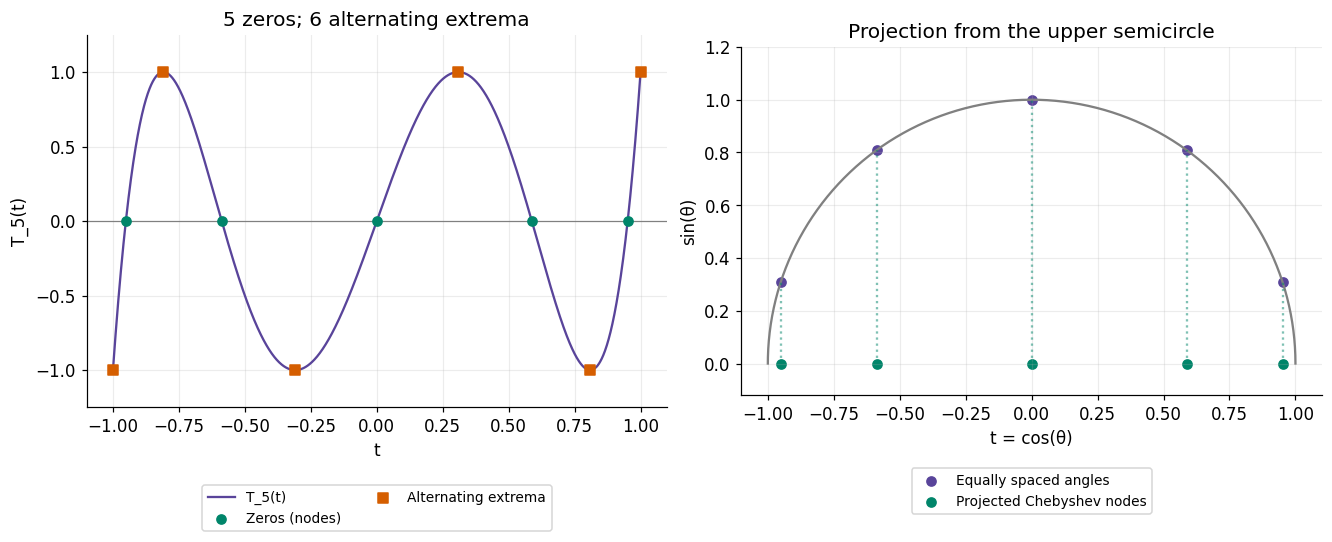

**Here k = 5.** There are 5 roots, so using them as interpolation nodes gives degree at most **n = 4**. The leading coefficient of T_5 is 16. The roots are interior points; the endpoints are extrema, not roots.

In [5]:
def chebyshev_explorer(k=5):
    t = np.linspace(-1, 1, 2001)
    angles = (2 * np.arange(k) + 1) * np.pi / (2 * k)
    roots = np.cos(angles)
    extrema = np.cos(np.arange(k + 1) * np.pi / k)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
    axes[0].plot(t, chebyshev_T(k, t), color="#59449A", label=f"T_{k}(t)")
    axes[0].scatter(
        roots,
        np.zeros(k),
        marker="o",
        color="#00856A",
        label="Zeros (nodes)",
        zorder=4,
    )
    axes[0].scatter(
        extrema,
        chebyshev_T(k, extrema),
        marker="s",
        color="#D55E00",
        label="Alternating extrema",
        zorder=4,
    )
    axes[0].axhline(0, color="gray", lw=0.8)
    axes[0].set(
        xlabel="t",
        ylabel=f"T_{k}(t)",
        title=f"{k} zeros; {k + 1} alternating extrema",
        ylim=(-1.25, 1.25),
    )
    axes[0].legend(
        fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.19), ncol=2
    )
    theta = np.linspace(0, np.pi, 400)
    axes[1].plot(np.cos(theta), np.sin(theta), color="gray")
    for x, y in zip(roots, np.sin(angles)):
        axes[1].plot([x, x], [0, y], color="#00856A", alpha=0.5, ls=":")
    axes[1].scatter(
        roots, np.sin(angles), color="#59449A", label="Equally spaced angles"
    )
    axes[1].scatter(
        roots, np.zeros(k), color="#00856A", label="Projected Chebyshev nodes"
    )
    axes[1].set(
        xlabel="t = cos(θ)",
        ylabel="sin(θ)",
        title="Projection from the upper semicircle",
        ylim=(-0.12, 1.2),
    )
    axes[1].set_aspect("equal", adjustable="box")
    axes[1].legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.19))
    text = (
        f"**Here k = {k}.** There are {k} roots, so using them as"
        f" interpolation nodes gives degree at most **n = {k - 1}**. The"
        f" leading coefficient of T_{k} is {2 ** (k - 1):,}. The roots are"
        " interior points; the endpoints are extrema, not roots."
    )
    return fig, text


chebyshev_controls = interactive_demo(
    chebyshev_explorer,
    {
        "k": control(
            "IntSlider", 5, min=1, max=15, description="Chebyshev degree k"
        ),
    },
)


## 5. Why its zeros minimize the nodal product

Our interpolant has degree at most $n$, but its nodal product has degree $n+1$.
We therefore use the **zeros of $T_{n+1}$**, not the zeros of $T_n$:

$$\boxed{x_j=\cos\!\left(\frac{(2j+1)\pi}{2(n+1)}\right),\quad j=0,\ldots,n.}$$

Since $T_{n+1}$ has leading coefficient $2^n$, dividing by $2^n$ makes it monic.
It has the same roots as the nodal product, so

$$\boxed{\omega_{n+1}^{\mathrm{Cheb}}(x)
=\prod_{j=0}^{n}(x-x_j)=2^{-n}T_{n+1}(x).}$$

Consequently,

$$\boxed{\max_{x\in[-1,1]}|\omega_{n+1}^{\mathrm{Cheb}}(x)|=2^{-n}.}$$

**Minimax theorem.** Among all monic polynomials of degree $n+1$, the scaled polynomial
$2^{-n}T_{n+1}$ has the smallest possible maximum absolute value on $[-1,1]$.
Its roots are distinct and inside the interval, so it solves our node-placement problem.

### Why the alternating peaks force optimality

Let $q(x)=2^{-n}T_{n+1}(x)$. At its $n+2$ ordered extrema, $q$ alternates between
$+2^{-n}$ and $-2^{-n}$. Suppose a monic polynomial $r$ of the same degree were
strictly smaller in maximum absolute value. Then $q-r$ would have the same alternating
signs at those extrema. By the intermediate value theorem, $q-r$ would have at least
$n+1$ distinct zeros, one between each pair of consecutive extrema.

But the leading terms cancel, so $q-r$ has degree at most $n$. It cannot have $n+1$
distinct zeros unless it is the zero polynomial, which would contradict the supposed
strict improvement. No monic competitor can have a smaller maximum.

### What is — and is not — optimized

Chebyshev roots minimize **$\|\omega_{n+1}\|_\infty$** and therefore minimize the
remainder **upper bound** based on a fixed $M_{n+1}$.
They need not minimize the actual error $\|f-p_n\|_\infty$ for a particular function.
The derivative factor can vary with the nodes through $\xi_x$.
Also, changing $n$ changes both the derivative order and the factorial, so the shrinking
factor $2^{-n}$ alone does not prove convergence for every function.

### Moving from $[-1,1]$ to $[a,b]$

Use $x=c+ht$, where $c=(a+b)/2$ and $h=(b-a)/2$. The mapped nodes are

$$x_j=\frac{a+b}{2}+\frac{b-a}{2}
\cos\!\left(\frac{(2j+1)\pi}{2(n+1)}\right).$$

Each difference contributes a factor $h$, hence

$$\omega_{n+1}^{\mathrm{Cheb}}(x)
=h^{n+1}2^{-n}T_{n+1}\!\left(\frac{x-c}{h}\right),$$
$$\boxed{\|\omega_{n+1}^{\mathrm{Cheb}}\|_{\infty,[a,b]}
=h^{n+1}2^{-n}=\frac{(b-a)^{n+1}}{2^{2n+1}}.}$$

For example, degree $n=2$ on $[-1,1]$ uses the three roots of
$T_3(x)=4x^3-3x$: $-\sqrt{3}/2,0,\sqrt{3}/2$.
Their product is $x^3-3x/4=T_3(x)/4$ and its maximum absolute value is $1/4$.

**Terminology:** These are Chebyshev **root nodes** (also called Chebyshev–Gauss nodes),
matching `cheby_lagrange.m`. Chebyshev–Lobatto nodes $\cos(j\pi/n)$ include the endpoints
and are a different node set. The exact unconstrained minimax product above uses roots.

## 6. See the quantity we are minimizing

The next experiment uses **only the nodes**. No target function or data values are involved.
The left panel plots the signed product; the right plots its absolute value. Both are
divided by the exact optimal norm
$C=h^{n+1}2^{-n}$ so that the optimal largest height is always **1**.

The horizontal lines at $\pm1$ in the signed plot mark the optimal envelope.
If the other curves are very large, select **Chebyshev only** to inspect the equal peaks.
Changing the interval changes the unscaled norm, even though this normalized shape is unchanged.

Box(children=(IntSlider(value=8, continuous_update=False, description='Interpolant degree n', layout=Layout(wi…

HTML(value='')

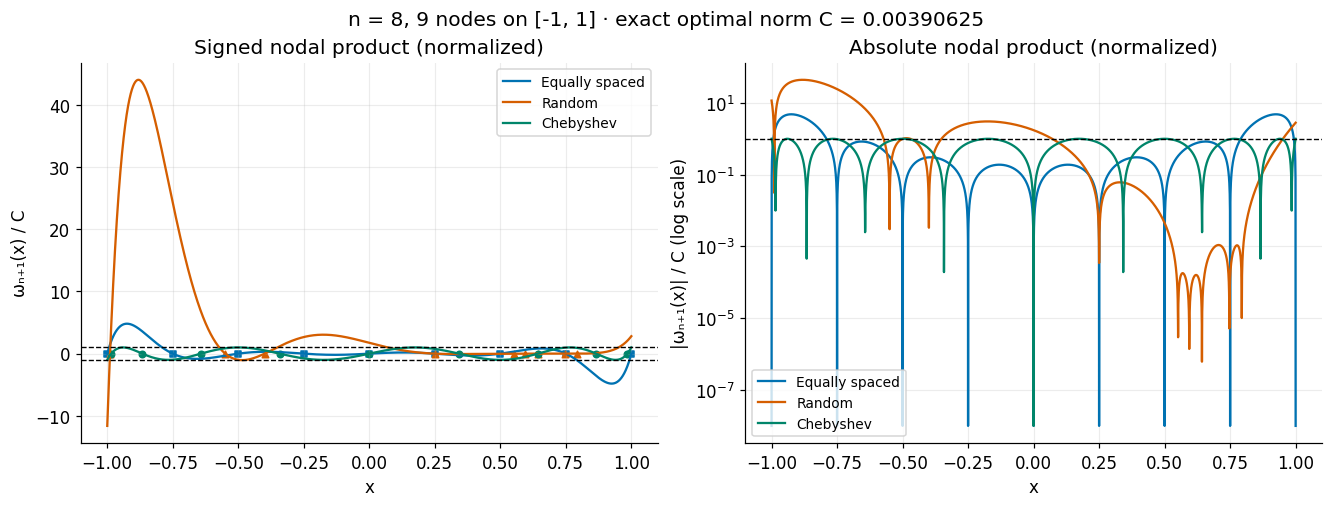

| Nodes | Sampled max absolute product | Ratio to exact optimal norm |
| --- | --- | --- |
| Equally spaced | 0.01880321 | 4.81362 |
| Random | 0.1718648 | 43.9974 |
| Chebyshev | 0.00390625 | 1 |

The theorem gives **ratio 1 exactly** for Chebyshev roots. Other maxima are grid estimates. Chebyshev extrema are included in the evaluation grid. Zeros are floored at 10⁻⁸ only for the log plot.

In [6]:
def product_explorer(
    n=8, seed=7, interval="[-1, 1]", pin_endpoints=False, chebyshev_only=False
):
    a, b = {
        "[-1, 1]": (-1.0, 1.0),
        "[0, 1]": (0.0, 1.0),
        "[0, 4]": (0.0, 4.0),
    }[interval]
    c, h = (a + b) / 2, (b - a) / 2
    extrema = c + h * np.cos(np.arange(n + 2) * np.pi / (n + 1))
    # Include the known Chebyshev extrema as well as a dense uniform grid.
    z = np.sort(np.unique(np.r_[np.linspace(a, b, 4001), extrema]))
    C = optimal_product_norm(n, a, b)
    families = ["Chebyshev"] if chebyshev_only else list(COLORS)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    rows = []
    for family in families:
        nodes = make_nodes(family, n, a, b, seed, pin_endpoints)
        product = node_product(z, nodes)
        axes[0].plot(z, product / C, color=COLORS[family], label=family)
        axes[0].scatter(
            nodes,
            np.zeros(n + 1),
            color=COLORS[family],
            marker=MARKERS[family],
            s=18,
        )
        axes[1].semilogy(
            z,
            np.maximum(np.abs(product) / C, 1e-8),
            color=COLORS[family],
            label=family,
        )
        rows.append([
            family,
            f"{np.max(np.abs(product)):.7g}",
            f"{np.max(np.abs(product)) / C:.6g}",
        ])
    axes[0].axhline(1, color="black", ls="--", lw=0.9)
    axes[0].axhline(-1, color="black", ls="--", lw=0.9)
    axes[1].axhline(1, color="black", ls="--", lw=0.9)
    axes[0].set(
        xlabel="x",
        ylabel="ωₙ₊₁(x) / C",
        title="Signed nodal product (normalized)",
    )
    axes[1].set(
        xlabel="x",
        ylabel="|ωₙ₊₁(x)| / C (log scale)",
        title="Absolute nodal product (normalized)",
    )
    for ax in axes:
        ax.legend(fontsize=9)
    fig.suptitle(
        f"n = {n}, {n + 1} nodes on [{a:g}, {b:g}] · exact optimal norm C ="
        f" {C:.6g}"
    )
    summary = markdown_table(
        [
            "Nodes",
            "Sampled max absolute product",
            "Ratio to exact optimal norm",
        ],
        rows,
    )
    summary += (
        "\n\nThe theorem gives **ratio 1 exactly** for Chebyshev roots. Other"
        " maxima are grid estimates. Chebyshev extrema are included in the"
        " evaluation grid. Zeros are floored at 10⁻⁸ only for the log plot."
    )
    return fig, summary


product_controls = interactive_demo(
    product_explorer,
    {
        "n": control(
            "IntSlider", 8, min=1, max=20, description="Interpolant degree n"
        ),
        "seed": control(
            "IntSlider", 7, min=0, max=99, description="Random seed"
        ),
        "interval": control(
            "Dropdown",
            "[-1, 1]",
            options=["[-1, 1]", "[0, 1]", "[0, 4]"],
            description="Interval",
        ),
        "pin_endpoints": control(
            "Checkbox", False, description="Pin random endpoints"
        ),
        "chebyshev_only": control(
            "Checkbox", False, description="Chebyshev only"
        ),
    },
)


## 7. Example: an error that is exactly the nodal product

Let $f(x)=x^{n+1}$ and interpolate it with a polynomial of degree at most $n$.
The difference $f-p_n$ is monic of degree $n+1$ and vanishes at every node. Therefore

$$\boxed{f(x)-p_n(x)=\omega_{n+1}(x).}$$

Equivalently, $f^{(n+1)}=(n+1)!$, so the derivative factor in the remainder is exactly $1$.
For this example, minimizing the nodal product **does** minimize the actual maximum
interpolation error over all node choices.

For $f(x)=x^3$ and $n=2$:

| Nodes | Interpolant | Exact maximum error on $[-1,1]$ |
|---|---|---|
| Equally spaced: $-1,0,1$ | $p_2(x)=x$ | $2/(3\sqrt{3})\approx0.384900$ |
| Chebyshev: $-\sqrt{3}/2,0,\sqrt{3}/2$ | $p_2(x)=3x/4$ | $1/4=0.25$ |

The subscript indicates degree **at most** two: both interpolants happen to be linear.

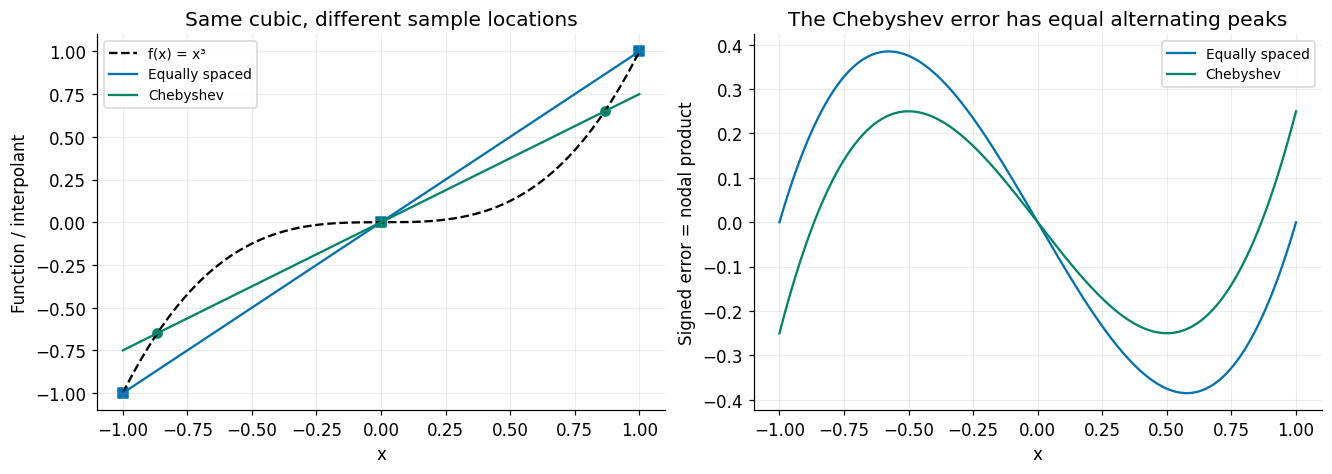

Here the error-product identity is exact in mathematics; plotted computations use floating-point arithmetic.

In [7]:
n = 2
z = np.linspace(-1, 1, 4001)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
axes[0].plot(z, z**3, "k--", label="f(x) = x³")
for family in ["Equally spaced", "Chebyshev"]:
    nodes = make_nodes(family, n)
    p = interpolate(nodes, nodes**3, z)
    axes[0].plot(z, p, color=COLORS[family], label=family)
    axes[0].scatter(
        nodes, nodes**3, color=COLORS[family], marker=MARKERS[family]
    )
    axes[1].plot(z, z**3 - p, color=COLORS[family], label=family)
axes[0].set(
    xlabel="x",
    ylabel="Function / interpolant",
    title="Same cubic, different sample locations",
)
axes[1].set(
    xlabel="x",
    ylabel="Signed error = nodal product",
    title="The Chebyshev error has equal alternating peaks",
)
for ax in axes:
    ax.legend(fontsize=9)
show_result((
    fig,
    (
        "Here the error-product identity is exact in mathematics; plotted"
        " computations use floating-point arithmetic."
    ),
))


## 8. Return to the Runge function — now with Chebyshev nodes

Repeat the original comparison with **all three node choices**.
Try $n=8,12,20$, keeping the same degree and the same target function in all panels.
Changing `alpha` changes the Runge function, not the node formula.

The function menu also contains two useful contrasts:

- **Exponential:** $f(x)=e^x$ is very well approximated even at modest degrees.
  Equal spacing need not produce a large error.
- **Absolute value:** $f(x)=|x|$ has a corner at zero. We can interpolate it, but it does
  not satisfy the smoothness hypothesis of the $(n+1)$st-derivative remainder theorem.
  The nodal-product minimax theorem still holds; that smooth-function error bound is unavailable.

`alpha` affects only the Runge choice. All examples in this panel use $[-1,1]$.

Box(children=(IntSlider(value=12, continuous_update=False, description='Degree n', layout=Layout(width='310px'…

HTML(value='')

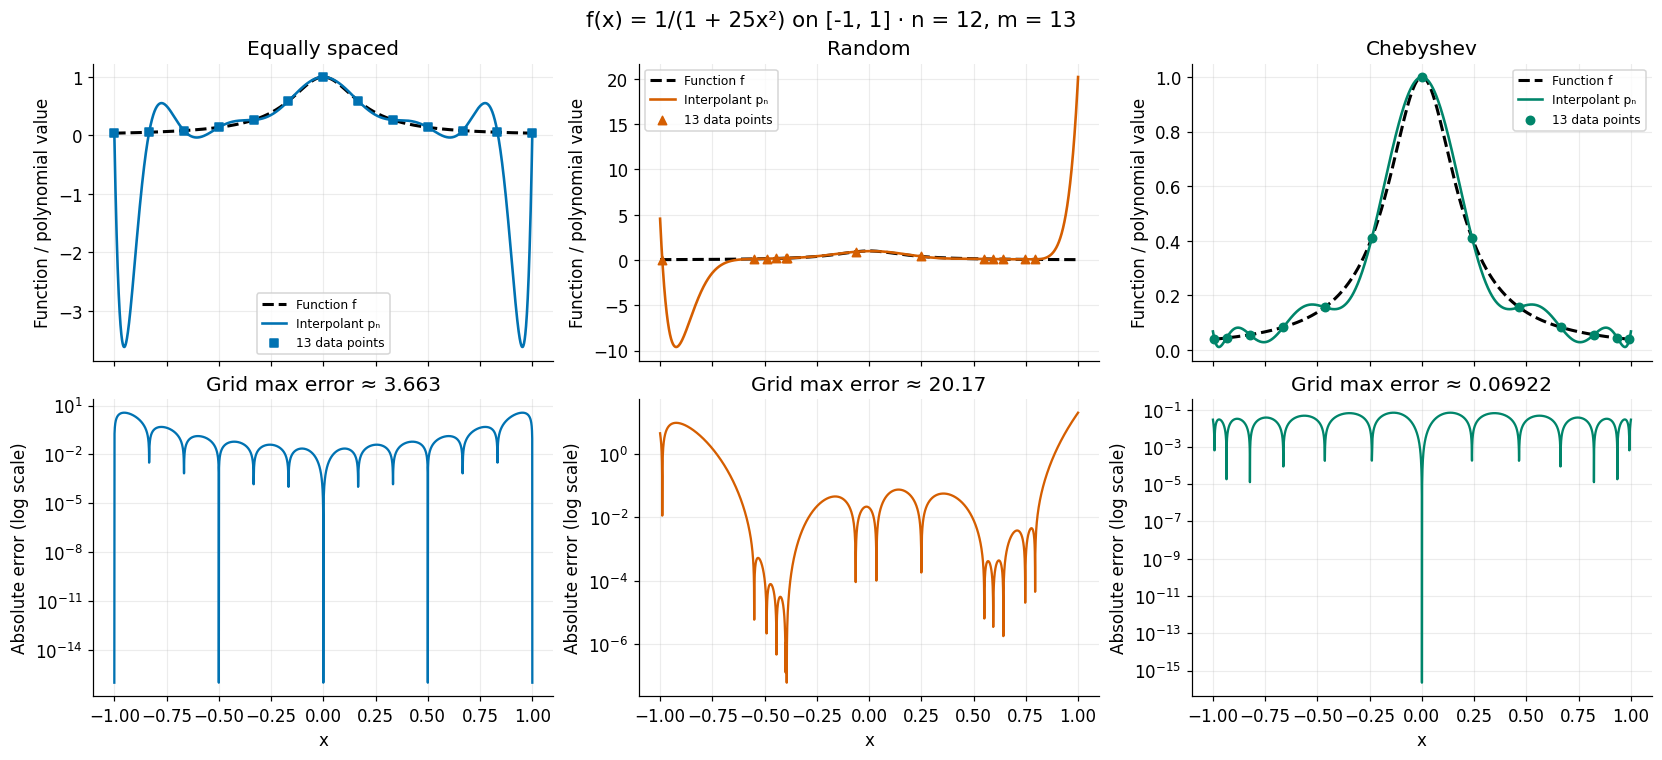

| Nodes | Max error on grid (estimate) | Grid location of max | Residual at data nodes |
| --- | --- | --- | --- |
| Equally spaced | 3.66338 | -0.95250 | 0.00e+00 |
| Random | 20.174 | 1.00000 | 0.00e+00 |
| Chebyshev | 0.0692157 | 0.13600 | 0.00e+00 |

Errors are sampled at 4,001 evaluation points, including interval endpoints. They are estimates of the continuous maximum, not rigorous bounds. Values below 10⁻¹⁶ are drawn at 10⁻¹⁶ only on the log plots; the table uses unmodified errors. Random nodes usually leave unsampled gaps at both ends; evaluating there is extrapolation beyond the outermost sampled nodes, even though it is inside the target interval.

In [8]:
def full_comparison(
    n=12, seed=7, alpha=25, function="Runge", pin_endpoints=False
):
    return compare_interpolants(
        n=n,
        seed=seed,
        alpha=alpha,
        function=function,
        pin_endpoints=pin_endpoints,
        include_chebyshev=True,
    )


comparison_controls = interactive_demo(
    full_comparison,
    {
        "n": control("IntSlider", 12, min=2, max=24, description="Degree n"),
        "seed": control(
            "IntSlider", 7, min=0, max=99, description="Random seed"
        ),
        "alpha": control(
            "IntSlider", 25, min=1, max=100, description="Runge parameter α"
        ),
        "function": control(
            "Dropdown",
            "Runge",
            options=["Runge", "Exponential", "Absolute value"],
            description="Function",
        ),
        "pin_endpoints": control(
            "Checkbox", False, description="Pin random endpoints"
        ),
    },
)


### Increasing degree: use many random trials

A single random seed is not representative of every random choice. The next plot shows
the Runge error versus degree for equal spacing and Chebyshev roots, together with the
**median** and **10th–90th percentile range** from 30 independent random node sets at each degree.
The shaded range is a descriptive range of trials, not a confidence interval or a bound.

All errors are sampled-grid estimates. Degrees use new node sets and are not a nested
sequence. For very clustered random nodes, numerical sensitivity can also affect the
computed polynomial; stable evaluation cannot eliminate ill-conditioning of the problem.

Box(children=(IntSlider(value=20, continuous_update=False, description='Largest degree', layout=Layout(width='…

HTML(value='')

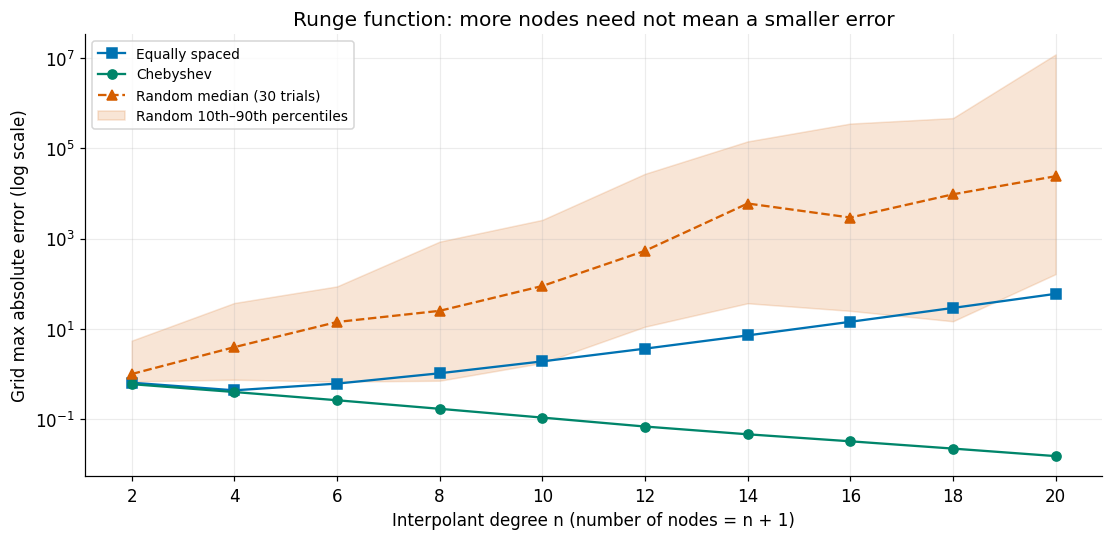

| Degree n | Equally spaced | Random median | Chebyshev |
| --- | --- | --- | --- |
| 2 | 0.6462 | 1.004 | 0.6006 |
| 4 | 0.4384 | 3.954 | 0.402 |
| 6 | 0.6169 | 14.25 | 0.2642 |
| 8 | 1.045 | 25.17 | 0.1708 |
| 10 | 1.916 | 89.26 | 0.1092 |
| 12 | 3.663 | 535.9 | 0.06922 |
| 14 | 7.195 | 5975 | 0.0466 |
| 16 | 14.39 | 2921 | 0.03261 |
| 18 | 29.19 | 9548 | 0.02249 |
| 20 | 59.82 | 2.398e+04 | 0.01533 |

In [9]:
def degree_study(max_degree=20, seed=7, pin_endpoints=False):
    degrees = np.arange(2, max_degree + 1, 2)
    z = np.linspace(-1, 1, 2001)

    def f(x):
        return 1 / (1 + 25 * np.asarray(x) ** 2)

    truth = f(z)
    rng = np.random.default_rng(seed)
    eq, cheb, medians, low, high = [], [], [], [], []
    for n in degrees:
        for family, result in [("Equally spaced", eq), ("Chebyshev", cheb)]:
            x = make_nodes(family, int(n))
            result.append(
                float(np.max(np.abs(truth - interpolate(x, f(x), z))))
            )
        errors = []
        for trial in range(30):
            trial_seed = int(rng.integers(0, 2**31 - 1))
            x = make_nodes(
                "Random", int(n), seed=trial_seed, pin_endpoints=pin_endpoints
            )
            error = float(np.max(np.abs(truth - interpolate(x, f(x), z))))
            if not np.isfinite(error):
                raise ArithmeticError(
                    "Non-finite random trial; try a smaller degree or another"
                    " seed."
                )
            errors.append(error)
        low.append(np.percentile(errors, 10))
        medians.append(np.median(errors))
        high.append(np.percentile(errors, 90))
    fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
    ax.semilogy(
        degrees,
        eq,
        "s-",
        color=COLORS["Equally spaced"],
        label="Equally spaced",
    )
    ax.semilogy(
        degrees, cheb, "o-", color=COLORS["Chebyshev"], label="Chebyshev"
    )
    ax.semilogy(
        degrees,
        medians,
        "^--",
        color=COLORS["Random"],
        label="Random median (30 trials)",
    )
    ax.fill_between(
        degrees,
        low,
        high,
        color=COLORS["Random"],
        alpha=0.16,
        label="Random 10th–90th percentiles",
    )
    ax.set(
        xlabel="Interpolant degree n (number of nodes = n + 1)",
        ylabel="Grid max absolute error (log scale)",
        title="Runge function: more nodes need not mean a smaller error",
        xticks=degrees,
    )
    ax.legend(fontsize=9)
    rows = [
        [int(n), f"{e:.4g}", f"{r:.4g}", f"{c:.4g}"]
        for n, e, r, c in zip(degrees, eq, medians, cheb)
    ]
    return fig, markdown_table(
        ["Degree n", "Equally spaced", "Random median", "Chebyshev"], rows
    )


degree_controls = interactive_demo(
    degree_study,
    {
        "max_degree": control(
            "IntSlider",
            20,
            min=8,
            max=24,
            step=2,
            description="Largest degree",
        ),
        "seed": control(
            "IntSlider", 7, min=0, max=99, description="Experiment seed"
        ),
        "pin_endpoints": control(
            "Checkbox", False, description="Pin random endpoints"
        ),
    },
)


## 9. Example: a rigorous bound for $e^x$

For $f(x)=e^x$ on $[-1,1]$, every derivative is $e^x$, so we may take $M_{n+1}=e$.
For interpolation at Chebyshev roots,

$$\boxed{\|e^x-p_n\|_\infty\le\frac{e}{(n+1)!}\,2^{-n}.}$$

At $n=5$ we use **six roots of $T_6$**, and the bound is

$$\frac{e}{6!\,2^5}=\frac{e}{23040}\approx1.17981\times10^{-4}.$$

The horizontal dashed line below is a **rigorous bound** in exact arithmetic. The
reported observed error is a **sampled estimate**. The curve may sit well below the bound:
an upper bound need not be attained. We stop at degree 10 here to keep the experiment
above the floating-point noise floor.

Box(children=(IntSlider(value=5, continuous_update=False, description='Degree n', layout=Layout(width='310px')…

HTML(value='')

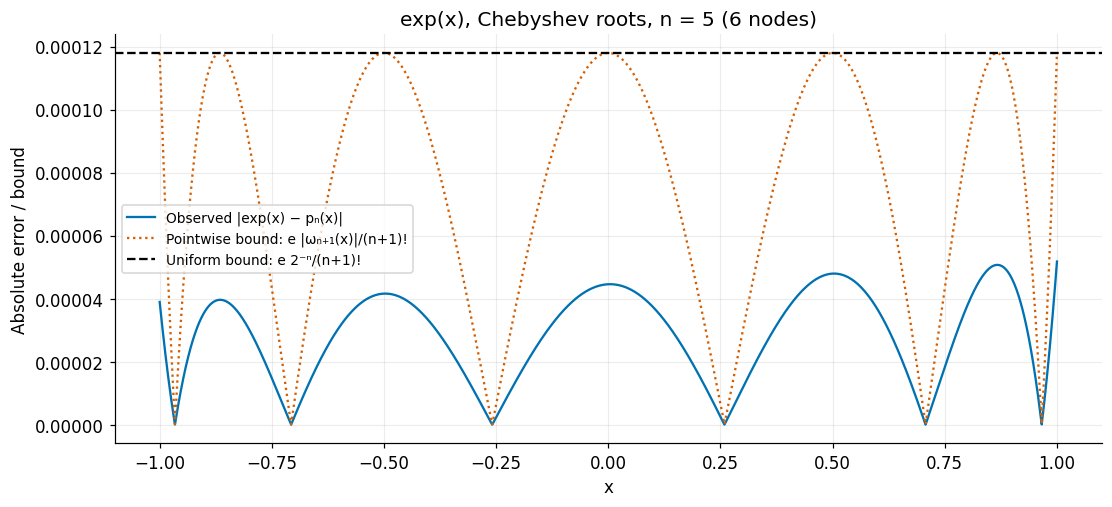

| Quantity | Value |
| --- | --- |
| Sampled maximum error | 5.17958477e-05 |
| Rigorous uniform bound (exact-arithmetic theorem) | 1.17980982e-04 |
| Observed error / bound | 0.43902 |

In [10]:
def exponential_bound(n=5):
    z = np.linspace(-1, 1, 4001)
    nodes = make_nodes("Chebyshev", n)
    p = interpolate(nodes, np.exp(nodes), z)
    error = np.abs(np.exp(z) - p)
    pointwise_bound = (
        math.e / math.factorial(n + 1) * np.abs(node_product(z, nodes))
    )
    uniform_bound = math.e / math.factorial(n + 1) * 2.0 ** (-n)
    fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
    ax.plot(z, error, color="#0072B2", label="Observed |exp(x) − pₙ(x)|")
    ax.plot(
        z,
        pointwise_bound,
        color="#D55E00",
        ls=":",
        label="Pointwise bound: e |ωₙ₊₁(x)|/(n+1)!",
    )
    ax.axhline(
        uniform_bound,
        color="black",
        ls="--",
        label="Uniform bound: e 2⁻ⁿ/(n+1)!",
    )
    ax.set(
        xlabel="x",
        ylabel="Absolute error / bound",
        title=f"exp(x), Chebyshev roots, n = {n} ({n + 1} nodes)",
    )
    ax.legend(fontsize=9)
    summary = markdown_table(
        ["Quantity", "Value"],
        [
            ["Sampled maximum error", f"{np.max(error):.8e}"],
            [
                "Rigorous uniform bound (exact-arithmetic theorem)",
                f"{uniform_bound:.8e}",
            ],
            ["Observed error / bound", f"{np.max(error) / uniform_bound:.5f}"],
        ],
    )
    return fig, summary


bound_controls = interactive_demo(
    exponential_bound,
    {
        "n": control("IntSlider", 5, min=1, max=10, description="Degree n"),
    },
)


## 10. Extension from the MATLAB files: random values are a different experiment

So far, **random nodes** meant random $x_j$ with $y_j=f(x_j)$ from a known function.
The original scripts also generated **random data values**. Here we draw $m=n+1$
numbers uniformly from $[0,1)$ and assign the **same ordered list of values** to each
family's sorted nodes. This makes comparisons reproducible, though the resulting
data pairs differ because their $x$-coordinates differ.

There is no specified underlying function in this experiment, so there is **no known
true interpolation error** to calculate. We instead show the polynomial and its
overshoot beyond the sampled data range. Exact interpolation can oscillate even with
Chebyshev nodes; the smooth-function remainder theorem cannot be used without a
suitable underlying function and derivative bound.

For noisy measurements, fitting a lower-degree model or using a piecewise method may
be more appropriate than forcing a high-degree global polynomial through every value.

Box(children=(IntSlider(value=10, continuous_update=False, description='Degree n', layout=Layout(width='310px'…

HTML(value='')

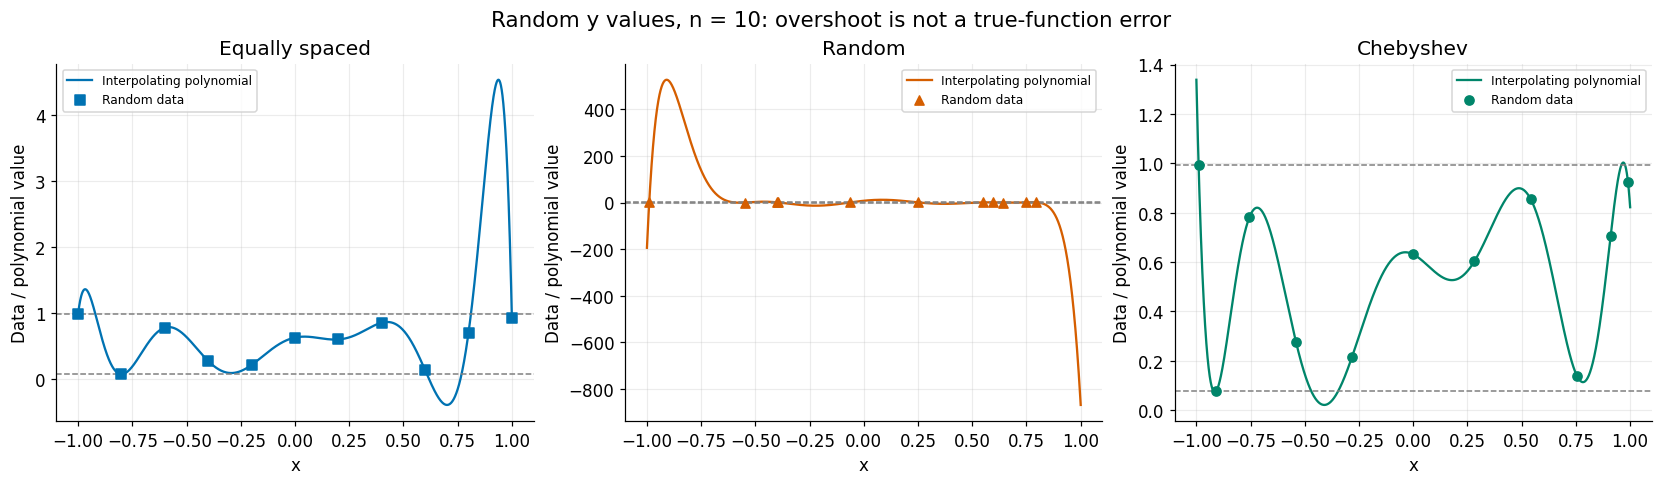

| Nodes | Grid min p | Grid max p | Largest excursion outside data range |
| --- | --- | --- | --- |
| Equally spaced | -0.388203 | 4.53335 | 3.54063 |
| Random | -868.786 | 527.043 | 868.863 |
| Chebyshev | 0.0215503 | 1.3385 | 0.345778 |

The common data range is [0.07661, 0.99273] (dashed lines). Panels use separate vertical scales and show the full curves.

In [11]:
def random_data_explorer(n=10, seed=7, pin_endpoints=False):
    z = np.linspace(-1, 1, 4001)
    # An independent random stream for y values, separate from the node seed.
    rng = np.random.default_rng(np.random.SeedSequence([seed, 12345]))
    values = rng.uniform(0, 1, n + 1)
    ymin, ymax = values.min(), values.max()
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), layout="constrained")
    rows = []
    for ax, family in zip(axes, COLORS):
        nodes = make_nodes(family, n, seed=seed, pin_endpoints=pin_endpoints)
        p = interpolate(nodes, values, z)
        ax.plot(z, p, color=COLORS[family], label="Interpolating polynomial")
        ax.scatter(
            nodes,
            values,
            color=COLORS[family],
            marker=MARKERS[family],
            label="Random data",
            zorder=3,
        )
        ax.axhline(ymin, color="gray", ls="--", lw=1)
        ax.axhline(ymax, color="gray", ls="--", lw=1)
        ax.set(xlabel="x", ylabel="Data / polynomial value", title=family)
        ax.legend(fontsize=8)
        overshoot = max(0.0, float(np.max(p) - ymax), float(ymin - np.min(p)))
        rows.append([
            family,
            f"{np.min(p):.6g}",
            f"{np.max(p):.6g}",
            f"{overshoot:.6g}",
        ])
    fig.suptitle(
        f"Random y values, n = {n}: overshoot is not a true-function error",
        fontsize=14,
    )
    summary = markdown_table(
        [
            "Nodes",
            "Grid min p",
            "Grid max p",
            "Largest excursion outside data range",
        ],
        rows,
    )
    summary += (
        f"\n\nThe common data range is [{ymin:.5f}, {ymax:.5f}] (dashed"
        " lines). Panels use separate vertical scales and show the full"
        " curves."
    )
    return fig, summary


random_data_controls = interactive_demo(
    random_data_explorer,
    {
        "n": control("IntSlider", 10, min=2, max=20, description="Degree n"),
        "seed": control(
            "IntSlider", 7, min=0, max=99, description="Random seed"
        ),
        "pin_endpoints": control(
            "Checkbox", False, description="Pin random endpoints"
        ),
    },
)


## 11. Check your understanding

1. If the MATLAB input is `m = 11`, what is $n$? Which Chebyshev polynomial supplies the nodes?
2. Why does the nodal polynomial have degree $n+1$ when the interpolant has degree at most $n$?
3. Why is $T_{n+1}$ divided by $2^n$ in the minimax argument?
4. Does Chebyshev interpolation minimize the sum of squared residuals? Explain what is actually minimized.
5. If you double the interval length while keeping $n$ fixed, by what factor does the optimal
   nodal-product norm change? Does that by itself determine the change in actual interpolation error?
6. For $f(x)=e^x$, find a degree that guarantees error at most $10^{-6}$ on $[-1,1]$ using the bound above.
7. Which part of the smooth-function error argument is unavailable for $f(x)=|x|$?

<details>
<summary><strong>Answers and discussion</strong></summary>

1. $n=10$; use the 11 roots of $T_{11}$.
2. The product has one linear factor per node, hence $n+1$ factors.
3. $T_{n+1}$ has leading coefficient $2^n$; division makes it monic, matching every nodal product.
4. No. Every interpolant already has zero residual at its data nodes. The minimized quantity is
   the maximum absolute nodal product over the entire interval, which controls a remainder bound.
5. A factor of $2^{n+1}$. The derivative bound on the larger interval may also change, and the
   actual error need not attain the bound.
6. $n=7$ suffices: $e/(8!\,2^7)\approx5.267\times10^{-7}$.
   The bound for $n=6$ is about $8.427\times10^{-6}$, so 7 is the smallest degree certified by this bound.
7. $|x|$ is not even differentiable at zero, so it is not in $C^{n+1}([-1,1])$ for the degrees used here.

</details>

## 12. A short version you can reuse

Once the setup and helper cells have run, the essential computation is only a few lines.
Edit the function, interval, or degree here. The full helper definitions earlier in the
notebook include the node formulas, mapping, and polynomial evaluation.

In [12]:
# Your own interpolation example:
a, b = -1.0, 1.0
n = 12  # degree at most 12: use 13 nodes


def f(x):
    return 1 / (1 + 25 * x**2)


nodes = make_nodes("Chebyshev", n, a=a, b=b)
values = f(nodes)
# evaluation points, not extra interpolation nodes
z = np.linspace(a, b, 4001)
p_values = interpolate(nodes, values, z)

print(f"Degree at most {n}; number of nodes = {len(nodes)}")
print(f"Sampled maximum error = {np.max(np.abs(f(z) - p_values)):.8g}")
print(
    f"Exact optimal nodal-product norm = {optimal_product_norm(n, a, b):.8g}"
)


Degree at most 12; number of nodes = 13
Sampled maximum error = 0.069215708
Exact optimal nodal-product norm = 0.00024414062


### Main conclusion

The interpolation remainder separates a **function-dependent derivative factor** from
a **node-dependent product**. Chebyshev root nodes minimize the largest magnitude of that
product by making it a scaled, monic Chebyshev polynomial with equal alternating peaks.
This explains why they are a principled choice of sample locations for global polynomial
interpolation, while preserving the distinction between an error bound and the actual error.

### Notes and references

- Adapted from the two supplied MATLAB demonstrations, `lagrange_interp.m` and
  `cheby_lagrange.m`, by Sarah Pollock (S. Pollock, MAD 4401, as credited in the source comments).
  Their input `m` means number of **interpolation** points. This notebook uses `n=m-1`
  in the sliders and prints both quantities.
- [NIST Digital Library of Mathematical Functions, §18.5](https://dlmf.nist.gov/18.5.E1):
  the trigonometric representation of Chebyshev polynomials.
- [NIST DLMF, §18.38(i)](https://dlmf.nist.gov/18.38.i): the monic Chebyshev minimax property.
- [SciPy: BarycentricInterpolator](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.BarycentricInterpolator.html):
  stable evaluation of the Lagrange interpolating polynomial.

**Numerical note.** Displayed errors combine approximation error and floating-point
effects. Theorems and bounds describe exact arithmetic. Large degrees and very close
random nodes can be especially sensitive. A dense-grid maximum is an estimate, not a
proof of the continuous maximum; the Chebyshev product norms and exponential bounds
are known analytically.

[↑ Module 2](README.md) · [Lagrange interpolation](01_lagrange_interpolation.ipynb)
